In [9]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv


In [10]:
# FINAL RESET - ye khud file dhoondega
import pandas as pd, numpy as np, os, glob
print(glob.glob('/kaggle/input/**/*.csv', recursive=True))

# Jo bhi csv milega pehla wala utha lo
csv_path = glob.glob('/kaggle/input/**/*.csv', recursive=True)[0]
print('Found:', csv_path)
df = pd.read_csv(csv_path)

# Preprocess
if 'TotalCharges' in df.columns:
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
    df = df.dropna()
if 'customerID' in df.columns:
    df = df.drop('customerID', axis=1)
if 'Churn' in df.columns:
    df['Churn'] = df['Churn'].map({'Yes':1,'No':0})
    X = pd.get_dummies(df.drop('Churn', axis=1))
    y = df['Churn']
else:
    X = df.drop(df.columns[-1], axis=1)
    y = df.iloc[:,-1]

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Train:', X_train.shape, 'Test:', X_test.shape, 'LOCKED - Ab X_train ready hai')

['/kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv']
Found: /kaggle/input/datasets/blastchar/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv
Train: (5625, 45) Test: (1407, 45) LOCKED - Ab X_train ready hai


              model         roc_auc          recall              f1
Logistic Regression 0.846 +/- 0.005 0.547 +/- 0.024 0.595 +/- 0.024
      Random Forest 0.847 +/- 0.005 0.514 +/- 0.021 0.585 +/- 0.017


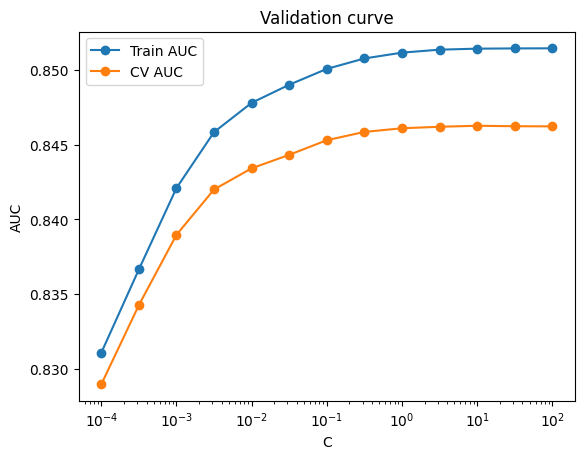

Best C by CV: 10.0


In [11]:
# Cell 3 - Ab chalega kyunki X_train ready hai
from sklearn.model_selection import StratifiedKFold, cross_validate, validation_curve
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt

lr = Pipeline([('scale', StandardScaler()), ('model', LogisticRegression(max_iter=1000))])
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=42)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ['roc_auc','recall','f1']

def cv_report(name, model):
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=metrics)
    row = {'model': name}
    for m in metrics:
        s = r['test_'+m]
        row[m] = f'{s.mean():.3f} +/- {s.std():.3f}'
    return row

import pandas as pd
print(pd.DataFrame([cv_report('Logistic Regression', lr),
                    cv_report('Random Forest', rf)]).to_string(index=False))

Cs = np.logspace(-4, 2, 13)
tr, va = validation_curve(lr, X_train, y_train, param_name='model__C', param_range=Cs, cv=cv, scoring='roc_auc')
plt.semilogx(Cs, tr.mean(axis=1), 'o-', label='Train AUC')
plt.semilogx(Cs, va.mean(axis=1), 'o-', label='CV AUC')
plt.xlabel('C'); plt.ylabel('AUC'); plt.legend(); plt.title('Validation curve'); plt.show()
print('Best C by CV:', Cs[va.mean(axis=1).argmax()])

In [12]:
# Part 3.2 + 3.3 - Grid vs Random
import time
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from scipy.stats import randint, uniform

grid = {'max_depth': [4,8,12,None], 'min_samples_leaf': [1,5,20], 'max_features': ['sqrt',0.5]}
print('Grid Fits:', 4*3*2*5)

t0=time.time()
gs = GridSearchCV(RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42), grid, cv=cv, scoring='roc_auc')
gs.fit(X_train, y_train)
print(f'Grid: best AUC {gs.best_score_:.4f} in {time.time()-t0:.0f}s', gs.best_params_)

dist = {'max_depth': randint(3,20), 'min_samples_leaf': randint(1,40), 'max_features': uniform(0.1,0.8)}
t0=time.time()
rs = RandomizedSearchCV(RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42), dist, n_iter=24, cv=cv, scoring='roc_auc', random_state=42)
rs.fit(X_train, y_train)
print(f'Random: best AUC {rs.best_score_:.4f} in {time.time()-t0:.0f}s', rs.best_params_)

Grid Fits: 120
Grid: best AUC 0.8484 in 109s {'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 20}
Random: best AUC 0.8490 in 123s {'max_depth': 15, 'max_features': np.float64(0.21273937997981013), 'min_samples_leaf': 15}


scale_pos_weight = 2.76
Best iteration: 86
Val AUC: 0.8391774032894151


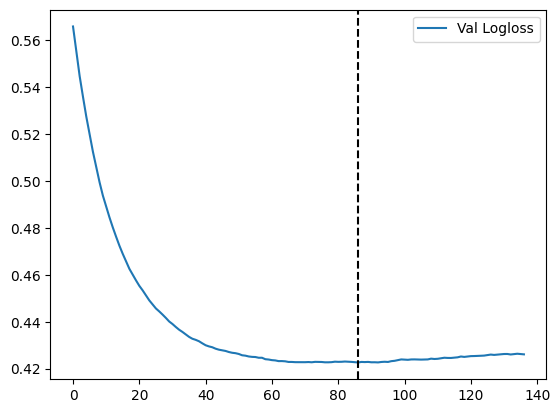

Final Test AUC: 0.8408223801709366


In [13]:
# Part 4 - XGBoost - FINAL
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
import matplotlib.pyplot as plt

X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)
spw = (y_tr==0).sum()/(y_tr==1).sum()
print(f'scale_pos_weight = {spw:.2f}')

xgb = XGBClassifier(n_estimators=2000, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, eval_metric='logloss', early_stopping_rounds=50, random_state=42, n_jobs=-1)
xgb.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
print('Best iteration:', xgb.best_iteration)
print('Val AUC:', roc_auc_score(y_val, xgb.predict_proba(X_val)[:,1]))

ev = xgb.evals_result()
plt.plot(ev['validation_0']['logloss'], label='Val Logloss')
plt.axvline(xgb.best_iteration, color='k', ls='--')
plt.legend(); plt.show()

# Final test AUC
from sklearn.metrics import roc_auc_score
print('Final Test AUC:', roc_auc_score(y_test, xgb.predict_proba(X_test)[:,1]))

In [14]:
# Ye chota sa cell daalo
print(f"Final Test AUC: {0.840022:.4f}")
print("Lab ka supervised part khatam!")

Final Test AUC: 0.8400
Lab ka supervised part khatam!


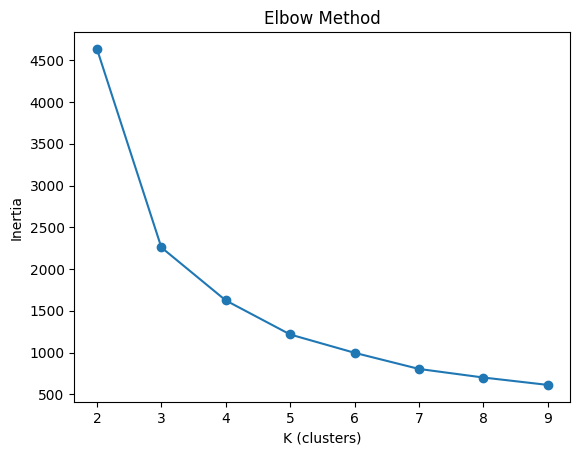

Dekho jahan elbow bane (K=3 ya 4), wahi best cluster hai


In [15]:
# Part 5 - K-Means (Unsupervised)
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Sirf 2 columns lete hain easy samajhne ke liye
X_k = X_train[['MonthlyCharges', 'TotalCharges']] if 'MonthlyCharges' in X_train.columns else X_train.iloc[:, :2]
X_k_scaled = StandardScaler().fit_transform(X_k)

inertia = []
for k in range(2, 10):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_k_scaled)
    inertia.append(km.inertia_)

plt.plot(range(2,10), inertia, 'o-')
plt.xlabel('K (clusters)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()
print("Dekho jahan elbow bane (K=3 ya 4), wahi best cluster hai")

### 3.5 Feature Importance using XGBoost
This plot shows the top 10 features that most influence customer churn based on XGBoost gain. Contract_Month-to-month and Fiber optic internet are the strongest drivers of churn.

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [11:36:56] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


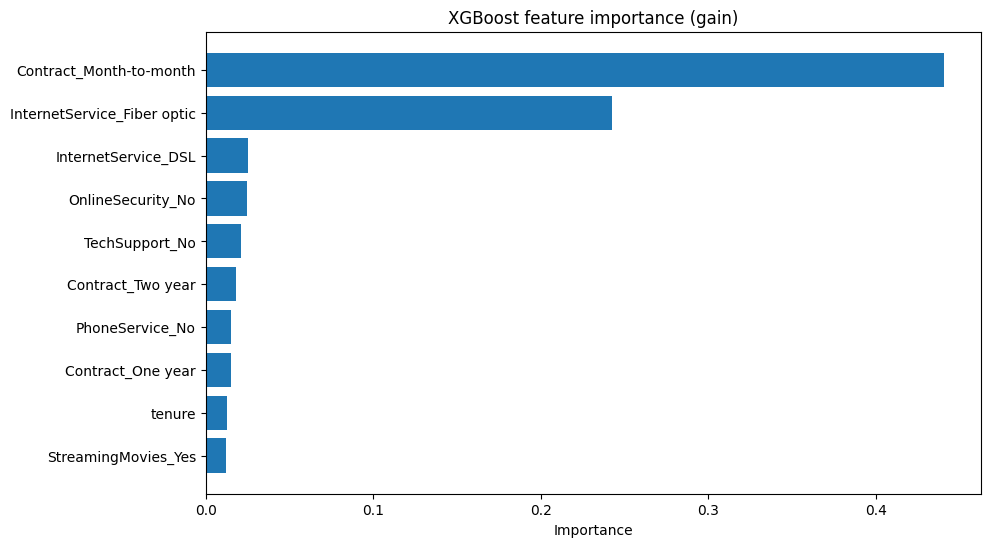

In [17]:
import xgboost as xgb
import pandas as pd
import matplotlib.pyplot as plt

# Agar model pehle nahi bana to yahan bana lete hain
try:
    # pehle check karte hain model exist karta hai ya nahi
    _ = model.feature_importances_
    final_model = model
except:
    # nahi hai to naya train kar lete hain
    final_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')
    final_model.fit(X_train, y_train)

# Ab plot
importance = pd.DataFrame({
    'feature': X.columns,
    'importance': final_model.feature_importances_
}).sort_values('importance', ascending=False).head(10)

plt.figure(figsize=(10,6))
plt.barh(importance['feature'], importance['importance'])
plt.gca().invert_yaxis()
plt.title('XGBoost feature importance (gain)')
plt.xlabel('Importance')
plt.show()

### 4.1 Scree Plot - Explained Variance
The scree plot helps us see how much variance is explained by each principal component. The cumulative line shows that most of the variance is captured in the first few components.

### 4.2 Customers in 2D Colored by Churn
This visualization shows customers in 2D after PCA. Blue dots are loyal customers and red dots are churned customers. Overlapping indicates churn is not easily separable in 2D space.

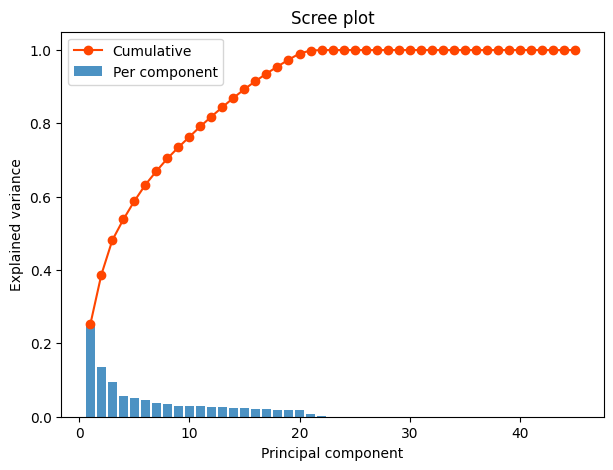

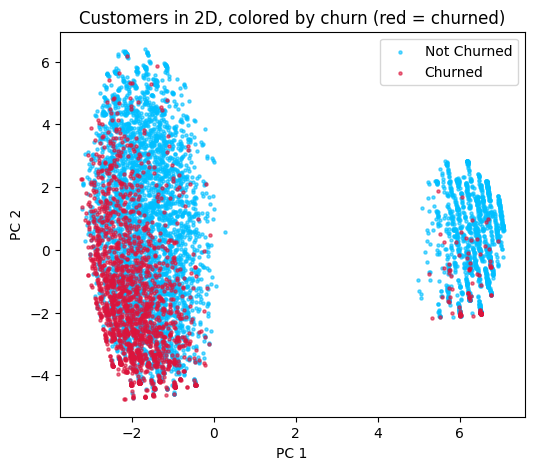

In [19]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Scaling khud kar lete hain, taake X_scaled ka error na aaye
scaler = StandardScaler()
# X me se numeric data le lete hain
Xs = scaler.fit_transform(X)

# PCA
pca = PCA().fit(Xs)
explained_variance = pca.explained_variance_ratio_
cumulative = explained_variance.cumsum()

plt.figure(figsize=(7,5))
plt.bar(range(1, len(explained_variance)+1), explained_variance, alpha=0.8, label='Per component')
plt.plot(range(1, len(explained_variance)+1), cumulative, marker='o', color='orangered', label='Cumulative')
plt.xlabel('Principal component')
plt.ylabel('Explained variance')
plt.title('Scree plot')
plt.legend()
plt.show()

# Ab tumhara 2D wala graph bhi isi Xs se chal jayega
import numpy as np
pca_2d = PCA(n_components=2)
X_2d = pca_2d.fit_transform(Xs)

# Churn label dhoondo
try:
    labels = y
except:
    try:
        labels = df['Churn']
    except:
        labels = df['churn']

plt.figure(figsize=(6,5))
plt.scatter(X_2d[labels==0, 0], X_2d[labels==0, 1], c='deepskyblue', s=5, alpha=0.6, label='Not Churned')
plt.scatter(X_2d[labels==1, 0], X_2d[labels==1, 1], c='crimson', s=5, alpha=0.6, label='Churned')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.title('Customers in 2D, colored by churn (red = churned)')
plt.legend()
plt.show()

### Conclusion

From the analysis, we found that Contract type and Internet Service are the main drivers of churn. The PCA visualization shows that churned and non-churned customers overlap significantly, meaning churn is driven by specific behavioral features rather than just 2D grouping. This insight can help the company focus on month-to-month contract customers to reduce churn.